# Stat 220 Midterm B: the take-home analysis
## Turnaround time at a bicycle repair shop

A repair shop switched to a new parts supplier for some jobs this year. The owner compared average turnaround before and after, saw no real difference, and is about to go back to the old supplier. They have asked you to check.

**100 points in all.** Run the setup cell first. Put your work in the cell under each task and your written answer in the markdown cell that follows it. Several tasks build on an earlier one, so work them in order.

---

**Getting help.** You may use AI, and you may ask the TAs, the professor, and each other. Two limits on the AI:

- Do not paste the whole notebook into it.
- Do not give it an entire task prompt and ask for the answer. If a prompt is unclear, you can paste a whole task prompt in to help clarify.

Everything else is open. Use the generate function in Colab or your editor to help write the code, ask about a specific piece of output, or have a piece of your work checked.

Use the methods from this course. A technique we have not covered is a sign that the AI has been asked for the answer rather than for help.

Add text or code boxes as needed, but do not change or modify the numbering of the tasks.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.model_selection import train_test_split

repairs = pd.read_csv("https://drbob-richardson.github.io/stat220/F2026/data/repair_jobs.csv")
repairs.head()

,days,parts_needed,parts_cost,tech_years,bike_type,new_supplier,ticket_number,shop_rating,quarter
0,4.32,5,86.03,1,mountain,0,2833,2,2
1,1.24,1,21.65,1,electric,0,2590,2,2
2,8.57,5,99.39,2,electric,1,5472,1,2
3,1.23,0,0.00,5,road,0,6510,5,3
4,0.72,2,38.79,2,commuter,0,3206,2,3


### Task 1.  (6 points)

Before you fit anything, decide what kind of model this question calls for. Name the family, say why it suits this outcome, and say what you need back from it that a random forest could not give you.

_Your answer:_

I would use a linear regression model because the outcome, days, is a continuous numeric variable.
I need coefficient estimates, p-values, confidence intervals, and AIC to understand and compare relationships in the data. A standard random forest is an algorithm model that can make predictions, but it does not directly provide these becuase those are the result of probability model.



### Task 2.  (8 points)

Make two plots that could be helpful concerning the shop's question. Then, in two or three sentences, say if there is anything notable you see that may affect modeling choices.

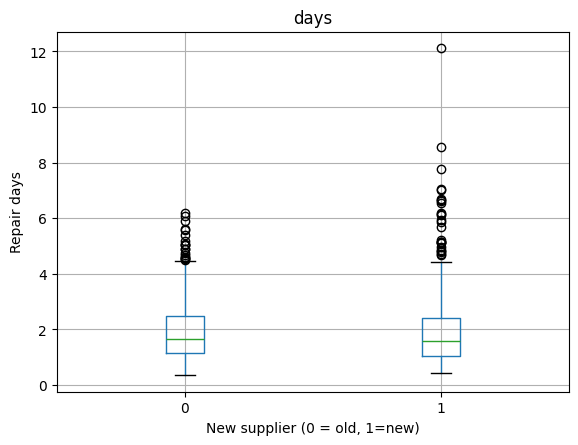

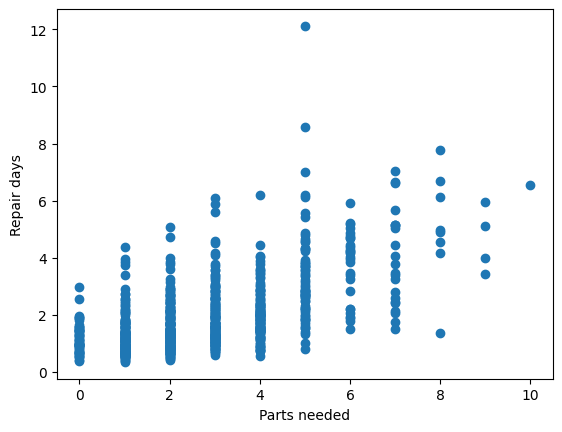

In [4]:

repairs.boxplot(column="days", by = "new_supplier")
plt.suptitle("")
plt.xlabel("New supplier (0 = old, 1=new)")
plt.ylabel("Repair days")
plt.show()

plt.scatter(repairs["parts_needed"], repairs["days"])
plt.xlabel("Parts needed")
plt.ylabel("Repair days")
plt.show()

_Your answer:_

The old-supplier repair times appear somewhat shorter and more concentrated, while a few new-supplier repairs took more than 8 days. However, the bodplots are nearly aligned, suggesting that the typical repair times and middle 50% spread are similar. The scatterplot shows a positive relationship, repairs needing more parts generally take longer, so I would include parts_needed in the model and check how the unusually long repair times affect the fit.



### Task 3.  (10 points)

The owner compared average repair time under the old and the new supplier, saw almost no difference, and is ready to drop the new one. Perform a formal statistical test for that comparison. Report both averages, the difference, a test, and a 95% interval, then say in two or three sentences what it does and does not establish.

In [8]:
old_days = repairs.loc[repairs["new_supplier"] ==0, "days"].dropna()
new_days = repairs.loc[repairs["new_supplier"] ==1, "days"].dropna()

old_mean = old_days.mean()
new_mean = new_days.mean()
difference  = new_mean - old_mean

test = stats.ttest_ind(new_days, old_days, equal_var=False)
interval = test.confidence_interval(confidence_level = 0.95)

print("Old supplier mean:", old_mean)
print("New supplier mean:", new_mean)
print("Difference(new-old):", difference)
print("Welch t statistic:", test.statistic)
print("p-value:", test.pvalue)
print(f"95% CI for difference:, [{interval.low:.2f}, {interval.high:.2f}]")


Old supplier mean: 1.9371820448877803
New supplier mean: 2.0159899749373436
Difference(new-old): 0.07880793004956321
Welch t statistic: 0.8515614542586756
p-value: 0.3947291653399472
95% CI for difference:, [-0.10, 0.26]


_Your answer:_



Result:

Old supplier mean: 1.94 days

New supplier mean: 2.02 days

Difference (new − old): 0.08 days

Welch’s t = 0.85

p = 0.395

95% CI for the difference: [−0.10, 0.26] days



Explanation:

The test did not find strong evidence that the suppliers have different average repair times because the p-value (0.395). However, this does not prove their averages are equal, and this comparison does not account for other factors such as parts needed, technician experience, or bike type.





### Task 4.  (8 points)

Now fit a model for repair time that includes the supplier indicator along with `parts_needed`, `tech_years` and `bike_type`. Report the supplier coefficient with its interval, interpret it in a sentence that names what is held fixed, and explain in two or three sentences why it differs from Task 3.

In [9]:
model4 = smf.ols(
    "days ~ new_supplier + parts_needed + tech_years + C(bike_type)",
    data = repairs
).fit()

supplier_coefficient = model4.params["new_supplier"]
ci_low, ci_high = model4.conf_int().loc["new_supplier"]

print(f"Supplier coefficient: {supplier_coefficient:.3f} days")
print(f"95% CI: [{ci_low:.3f}, {ci_high:.3f}] days")

Supplier coefficient: -0.428 days
95% CI: [-0.573, -0.282] days


_Your answer:_

The supplier coefficient is -0.428 days, with a 95% confidence interval of [-0.573 to -0.282] days. This means repairs using the old supplier,parts_needed, tech_years, and bike_type fixed. Compared with Task3, this model estimate the supplier difference while accounting for those variables. Task3 only compares the two overall averages, so this is a more controlled comparison oj jobs with similar recorded characteristics.




### Task 5.  (6 points)

Add `parts_cost` to the model from Task 4. Report the coefficient on `parts_needed` and its standard error before and after. Look at the p-value on `parts_cost` as well as the p-value on `parts_needed` before and after `parts_cost` was added. Explain in two or three sentences what is going on.

In [10]:
model5 = smf.ols(
    "days ~ new_supplier + parts_needed + tech_years + C(bike_type) + parts_cost",
    data = repairs
).fit()

print("Before (coefficient, SE, p-value):",
      model4.params["parts_needed"],
      model4.bse["parts_needed"],
      model4.pvalues["parts_needed"])

print("After (coeficient, SE, p-value): ",

      model5.params["parts_needed"],
      model5.bse["parts_needed"],
      model5.pvalues["parts_needed"])

print("parts_cost p-value:", model5.pvalues["parts_cost"])

Before (coefficient, SE, p-value): 0.46713585565081983 0.020281191701249417 2.791937322079404e-90
After (coeficient, SE, p-value):  0.43569365572101404 0.1051885892800134 3.812568488841022e-05
parts_cost p-value: 0.7607239793008576


_Your answer:_

The parts_needed coefficient changed slightly from 0.467 to 0.436 after adding parts_cost, while its standard error increased from 0.020 to 0.105, making the estimate less precise. Its p-value increased from 2.79 * 10^-90 to 3.81 * 10^-5 but remains below 0.05, while parts_cost had a p-value of 0.761. This suggests that parts_cost and parts_needed may overlap in the information they provided, making it harder to estimate their separate effects.



### Task 6.  (6 points)

Bike type has four levels. Report its coefficients, say which level is the baseline and how you can tell, and write the sentence that interprets one of the others. Say what would change if a different level were the baseline.

In [11]:
print(sorted(repairs["bike_type"].dropna().unique()))
print(model4.params.filter(like ="C(bike_type)"))

['commuter', 'electric', 'mountain', 'road']
C(bike_type)[T.electric]    0.746362
C(bike_type)[T.mountain]    0.147131
C(bike_type)[T.road]       -0.097884
dtype: float64


_Your answer:_

The baseline is commuter because no coefficient is listed for it. And the other three coefficients compare each bike type with commuter.
The coefficients are 0.746 days for electric, 0.147 days for mountain, and -0.098 days for road. Holding other predictors fixed, electric repairs are estimated to take 0.746 days longer. If a different level were the baseline, the coefficient values and comparisons would change, but the model's prediction would stay the same.


### Task 7.  (8 points)

Plot the residuals of the Task 4 model against its fitted values. Name what you see, and back it with a number: report the standard deviation of the residuals on the upper half of the fitted values divided by the standard deviation on the lower half. Say what this does to the intervals you reported in Task 4.

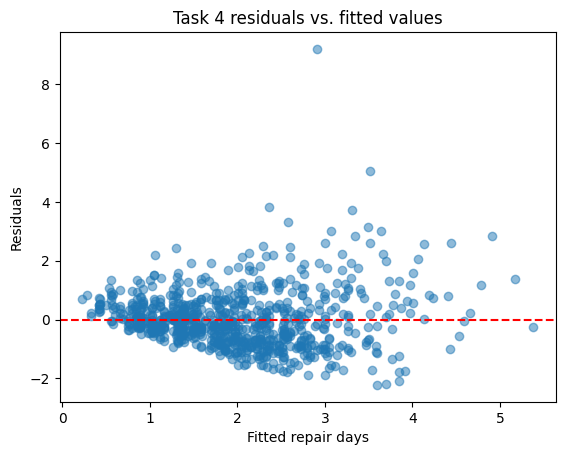

Upper-half SD: 1.2325272397336526
Lower-half SD: 0.590963079093708
Upper/lower SD ratio: 2.08562477646461


In [15]:
fitted = model4.fittedvalues
residuals = model4.resid

plt.scatter(fitted, residuals, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted repair days")
plt.ylabel("Residuals")
plt.title("Task 4 residuals vs. fitted values")
plt.show()


midpoint = fitted.median()

lower_sd = residuals[fitted <= midpoint].std()
upper_sd = residuals[fitted > midpoint].std()

print("Upper-half SD:", upper_sd)
print("Lower-half SD:", lower_sd)
print("Upper/lower SD ratio:", upper_sd / lower_sd)


_Your answer:_

The plot shows that residuals are more spread out at higher fitted repair times, with one large positive outlier. But lower fitted is more condensed with dots. The upper-half SD is 1.23 days and the lower-half SD is 0.59 days, giving a ratio of 2.09, so the upper-half spread is about twice as large. This unequal spread may take the usual task4 confidence intervals unreliable because they assume roughly constant residual variance.



### Task 8.  (10 points)

Fit the model again with the log of repair days as the outcome. Report the same spread ratio for the new residuals, say which model you would use and why, and write the sentence that interprets the supplier coefficient on the log scale. A coefficient of $b$ on a logged outcome is roughly a $100(e^{b}-1)%$ change.

_Your answer:_



### Task 9.  (8 points)

Fit a model for log repair days that starts with every predictor the shop records. Then cut it down to the columns that are carrying their weight, using a method from this course. Say which method you used, report what it kept and what it dropped, and say in two or three sentences whether the result changes anything about your answer to Task 4.

_Your answer:_



### Task 10.  (8 points)

Fit a decision tree for log repair days from parts needed, technician experience, bike type and supplier. Choose its depth with an appropriate method and say why that method works. For this tree, state how many different exact values can be predicted.

_Your answer:_



### Task 11.  (10 points)

Use the regression tree as a guide to recommend at least two new terms to add to the regression model from Task 8 that induce non-linearity. For each new term, check whether it improves the model or not.

_Your answer:_



### Task 12.  (6 points)

A customer brings in a commuter bike needing 4 parts, going to a technician with 2 years of experience, with parts from the new supplier. Predict the turnaround from the model you settled on from Task 11, give the interval you would quote them, and say in one sentence why that interval rather than the other.

_Your answer:_



### Task 13.  (6 points)

Write six to eight sentences to the shop owner. Cover what you found about the supplier, what you found about big jobs, how sure you are of each, and what they can and cannot do with it. Assume they have not taken this course.

_Your answer:_

